# Predicting Reported Extramarital Affairs Using Machine Learning
**Student name(s):** Abdallah Doleh

**Abstract.** This experiment analyzes 6,366 observations from Fair’s extramarital-affairs survey. We explore the variables with summary tables and seven charts, then compare a majority-class baseline, logistic regression, and a random forest using stratified cross-validation and an untouched test set. Associations are descriptive, not causal. The notebook is self-contained and runs in Google Colab without uploading a dataset.

## Table of Content
- [Problem](#problem)
- [Data Understanding](#data_understanding)
- [Data Preparation](#data_preparation)
- [Modeling](#modeling)
- [Evaluation](#evaluation)
- [References](#references)

## Problem <a id="problem"></a>
**Research question:** How well do available survey variables predict whether a respondent reports any extramarital affair? We compare predictive models with a baseline, consider class imbalance, and avoid causal interpretations. The target is `any_affair = (affairs > 0)`; the original count is excluded from predictors to prevent leakage.

## Data Understanding <a id="data_understanding"></a>

In [1]:
import sys, io, base64, zlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score,
                             ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay,
                             classification_report)
import sklearn
print('Python:', sys.version.split()[0])
print('pandas:', pd.__version__)
print('scikit-learn:', sklearn.__version__)
sns.set_theme(style='whitegrid', palette='deep')
DATA_B64 = (
    '...'
    'gnfqBw=='
)
df = pd.read_csv(io.BytesIO(zlib.decompress(base64.b64decode(''.join(DATA_B64)))))
print('Dataset shape:', df.shape)

Python: 3.13.16
pandas: 2.2.3
scikit-learn: 1.6.1
Dataset shape: (6366, 9)


### 1. Data dictionary and design
The response `affairs` records reported affairs; we define `any_affair = (affairs > 0)`. Predictor columns are `rate_marriage`, `age`, `yrs_married`, `children`, `religious`, `educ`, `occupation`, and `occupation_husb`. We exclude the original `affairs` variable from predictors to prevent leakage. The survey is observational and self-reported.

**Protocol:** Fixed 80/20 stratified holdout; five-fold stratified cross-validation on training data only; final test scores reported once. Standardization occurs inside the cross-validation pipeline.

In [2]:
display(df.head(8))
display(df.describe(include='all').T.round(2))
print('Missing values per column:')
display(df.isna().sum().to_frame('missing'))
print('Exact duplicate rows:', df.duplicated().sum())
df['any_affair'] = (df['affairs'] > 0).astype(int)
display(df['any_affair'].value_counts().rename(index={0:'No affair reported',1:'Any affair reported'}).to_frame('count'))

,rate_marriage,age,yrs_married,children,religious,educ,occupation,occupation_husb,affairs
0,3.0,32.0,9.0,3.0,3.0,17.0,2.0,5.0,0.111111
1,3.0,27.0,13.0,3.0,1.0,14.0,3.0,4.0,3.230769
2,4.0,22.0,2.5,0.0,1.0,16.0,3.0,5.0,1.400000
3,4.0,37.0,16.5,4.0,3.0,16.0,5.0,5.0,0.727273
4,5.0,27.0,9.0,1.0,1.0,14.0,3.0,4.0,4.666666
5,4.0,27.0,9.0,0.0,2.0,14.0,3.0,4.0,4.666666
6,5.0,37.0,23.0,5.5,2.0,12.0,5.0,4.0,0.852174
7,5.0,37.0,23.0,5.5,2.0,12.0,2.0,3.0,1.826086


,count,mean,std,min,25%,50%,75%,max
rate_marriage,6366.0,4.11,0.96,1.0,4.0,4.0,5.00,5.0
age,6366.0,29.08,6.85,17.5,22.0,27.0,32.00,42.0
yrs_married,6366.0,9.01,7.28,0.5,2.5,6.0,16.50,23.0
children,6366.0,1.40,1.43,0.0,0.0,1.0,2.00,5.5
religious,6366.0,2.43,0.88,1.0,2.0,2.0,3.00,4.0
educ,6366.0,14.21,2.18,9.0,12.0,14.0,16.00,20.0
occupation,6366.0,3.42,0.94,1.0,3.0,3.0,4.00,6.0
occupation_husb,6366.0,3.85,1.35,1.0,3.0,4.0,5.00,6.0
affairs,6366.0,0.71,2.20,0.0,0.0,0.0,0.48,57.6


Missing values per column:


,missing
rate_marriage,0
age,0
yrs_married,0
children,0
religious,0
educ,0
occupation,0
occupation_husb,0
affairs,0


Exact duplicate rows: 1039


,count
any_affair,
No affair reported,4313
Any affair reported,2053


### Exploratory data analysis — seven charts
The following charts examine class balance, age, years married, marital satisfaction, religiosity, correlations, and age versus years married. Patterns do not imply causation.

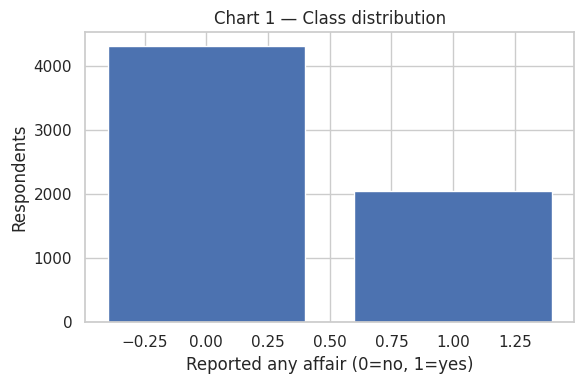

In [3]:
fig, ax = plt.subplots(figsize=(6,4))
ax.bar([0,1], df['any_affair'].value_counts().reindex([0,1]).values)
ax.set(title='Chart 1 — Class distribution', xlabel='Reported any affair (0=no, 1=yes)', ylabel='Respondents')
plt.tight_layout(); plt.show()

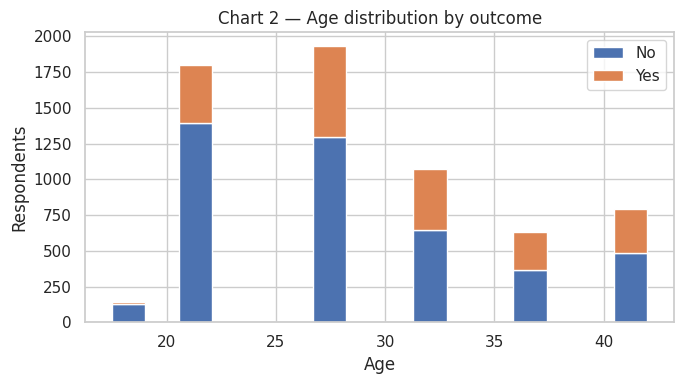

In [4]:
fig, ax = plt.subplots(figsize=(7,4))
ax.hist([df.loc[df.any_affair==0,'age'],df.loc[df.any_affair==1,'age']], bins=16, stacked=True, label=['No','Yes'])
ax.legend(); ax.set(title='Chart 2 — Age distribution by outcome', xlabel='Age', ylabel='Respondents')
plt.tight_layout(); plt.show()

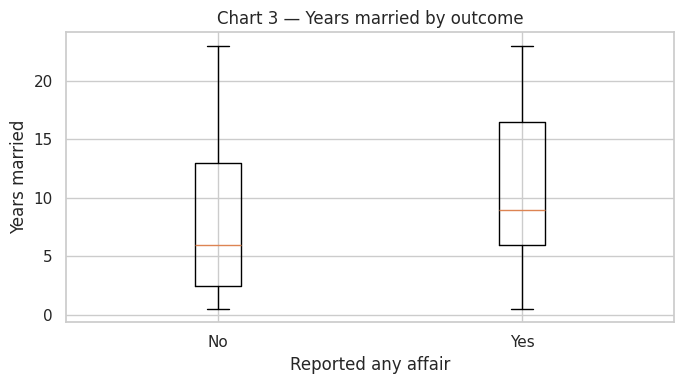

In [5]:
fig, ax = plt.subplots(figsize=(7,4))
ax.boxplot([df.loc[df.any_affair==0,'yrs_married'],df.loc[df.any_affair==1,'yrs_married']], tick_labels=['No','Yes'])
ax.set(title='Chart 3 — Years married by outcome', xlabel='Reported any affair', ylabel='Years married')
plt.tight_layout(); plt.show()

,affair_rate,respondents
rate_marriage,,
1.0,0.747,99
2.0,0.635,348
3.0,0.551,993
4.0,0.323,2242
5.0,0.181,2684


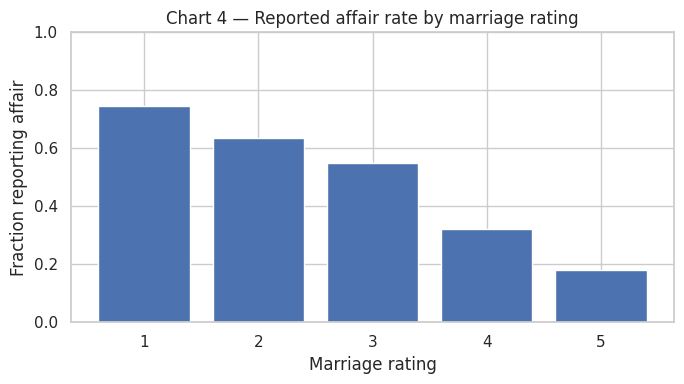

In [6]:
fig, ax = plt.subplots(figsize=(7,4))
r = df.groupby('rate_marriage')['any_affair'].agg(['mean','count'])
display(r.rename(columns={'mean':'affair_rate','count':'respondents'}).round(3))
ax.bar(r.index,r['mean']); ax.set(title='Chart 4 — Reported affair rate by marriage rating',xlabel='Marriage rating',ylabel='Fraction reporting affair',ylim=(0,1))
plt.tight_layout(); plt.show()

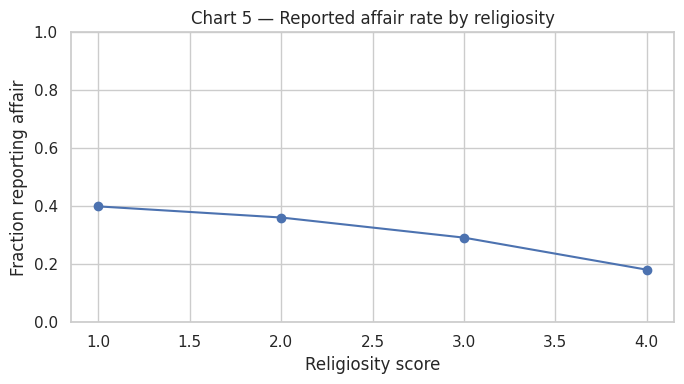

In [7]:
fig, ax = plt.subplots(figsize=(7,4))
r = df.groupby('religious')['any_affair'].mean()
ax.plot(r.index,r.values,marker='o'); ax.set(title='Chart 5 — Reported affair rate by religiosity',xlabel='Religiosity score',ylabel='Fraction reporting affair',ylim=(0,1))
plt.tight_layout(); plt.show()

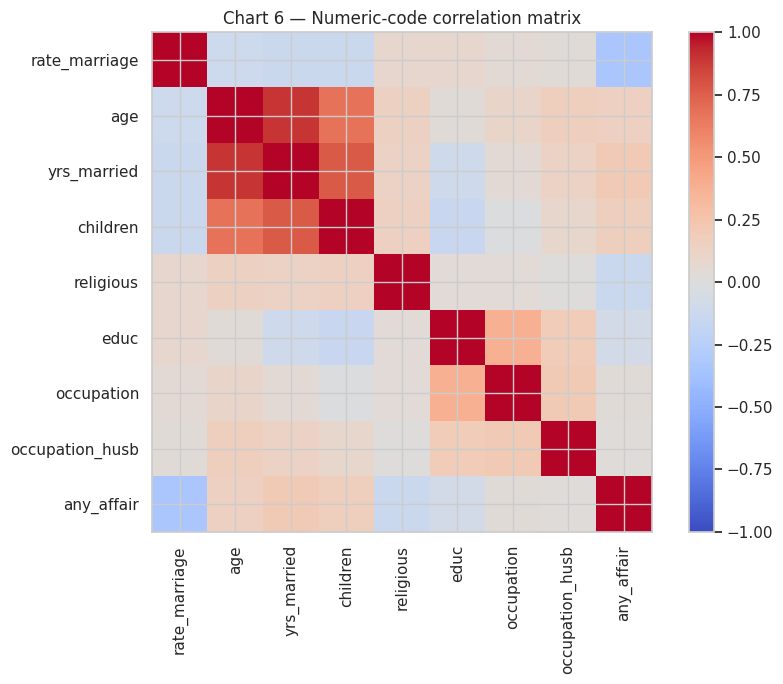

In [8]:
fig, ax = plt.subplots(figsize=(9,7))
corr = df.drop(columns='affairs').corr(numeric_only=True)
im = ax.imshow(corr,cmap='coolwarm',vmin=-1,vmax=1)
ax.set_xticks(range(len(corr.columns)),corr.columns,rotation=90)
ax.set_yticks(range(len(corr.columns)),corr.columns)
fig.colorbar(im,ax=ax); ax.set_title('Chart 6 — Numeric-code correlation matrix')
plt.tight_layout(); plt.show()

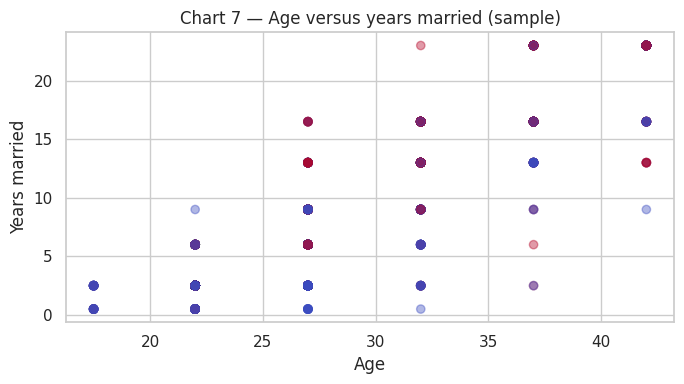

In [9]:
fig, ax = plt.subplots(figsize=(7,4))
sample = df.sample(n=min(1500,len(df)),random_state=42)
ax.scatter(sample.age,sample.yrs_married,c=sample.any_affair,cmap='coolwarm',alpha=.4)
ax.set(title='Chart 7 — Age versus years married (sample)',xlabel='Age',ylabel='Years married')
plt.tight_layout(); plt.show()

## Data Preparation <a id="data_preparation"></a>
The response is converted to a binary label; the original `affairs` column is removed to prevent target leakage. An 80/20 stratified split preserves class proportions. Logistic regression uses standardized inputs within its pipeline. The random forest uses the same predictors. Five-fold stratified cross-validation is performed on training data only.

## Modeling <a id="modeling"></a>
### 3. Modeling
`occupation` and `occupation_husb` are discrete codes, but for a compact comparison we retain their numeric encodings; this imposes an ordinal relationship in logistic regression and is a limitation. One-hot encoding would be a possible improvement. The baseline predicts the most frequent class. Logistic regression uses a standardized pipeline; random forest captures nonlinearities. Hyperparameters are pre-specified.

In [10]:
X = df.drop(columns=['affairs','any_affair']); y = df['any_affair']
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=.20,stratify=y,random_state=42)
models = {
    'Majority baseline': DummyClassifier(strategy='most_frequent'),
    'Logistic regression': make_pipeline(StandardScaler(),LogisticRegression(max_iter=2000,random_state=42)),
    'Random forest': RandomForestClassifier(n_estimators=180,min_samples_leaf=5,random_state=42,n_jobs=-1)
}
cv = StratifiedKFold(n_splits=5,shuffle=True,random_state=42)
scoring = {'roc_auc':'roc_auc','average_precision':'average_precision','balanced_accuracy':'balanced_accuracy','f1':'f1'}
rows=[]
for name,model in models.items():
    scores=cross_validate(model,X_train,y_train,cv=cv,scoring=scoring,n_jobs=1)
    rows.append({'model':name,**{metric+'_mean':scores['test_'+metric].mean() for metric in scoring},**{metric+'_sd':scores['test_'+metric].std() for metric in scoring}})
cv_table=pd.DataFrame(rows).set_index('model')
print('Training-only 5-fold cross-validation:'); display(cv_table.round(3))

Training-only 5-fold cross-validation:


,roc_auc_mean,average_precision_mean,balanced_accuracy_mean,f1_mean,roc_auc_sd,average_precision_sd,balanced_accuracy_sd,f1_sd
model,,,,,,,,
Majority baseline,0.500,0.322,0.500,0.000,0.000,0.000,0.000,0.000
Logistic regression,0.746,0.587,0.636,0.470,0.013,0.022,0.022,0.040
Random forest,0.751,0.576,0.640,0.481,0.016,0.014,0.014,0.027


## Evaluation <a id="evaluation"></a>
### 4. Held-out evaluation
ROC-AUC and average precision are threshold-independent; recall, precision, F1 and balanced accuracy use the default 0.5 decision threshold. Interpret scores against class prevalence.

In [11]:
test_rows={}; predictions={}
for name,model in models.items():
    model.fit(X_train,y_train)
    yp=model.predict(X_test); prob=model.predict_proba(X_test)[:,1]
    predictions[name]=(yp,prob)
    test_rows[name]={'accuracy':accuracy_score(y_test,yp),'balanced_accuracy':balanced_accuracy_score(y_test,yp),
        'precision':precision_score(y_test,yp,zero_division=0),'recall':recall_score(y_test,yp,zero_division=0),
        'f1':f1_score(y_test,yp,zero_division=0),'roc_auc':roc_auc_score(y_test,prob),
        'average_precision':average_precision_score(y_test,prob)}
test_table=pd.DataFrame(test_rows).T
print('Test prevalence:',round(y_test.mean(),3)); display(test_table.round(3))
print('Best model by training CV ROC-AUC:',cv_table['roc_auc_mean'].idxmax())

Test prevalence: 0.323


,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,average_precision
Majority baseline,0.677,0.500,0.000,0.000,0.000,0.500,0.323
Logistic regression,0.705,0.616,0.566,0.367,0.445,0.724,0.543
Random forest,0.688,0.604,0.524,0.367,0.432,0.710,0.512


Best model by training CV ROC-AUC: Random forest


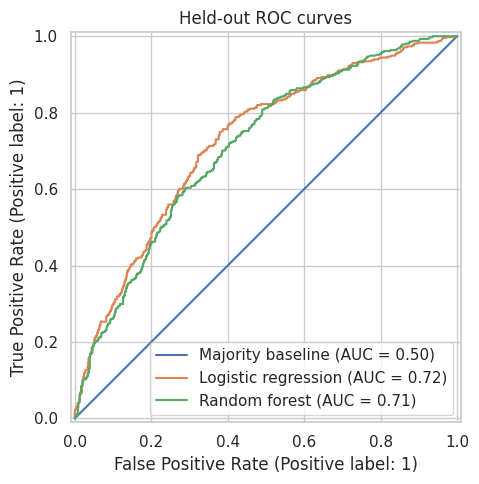

In [12]:
fig,ax=plt.subplots(figsize=(7,5))
for name,(_,prob) in predictions.items(): RocCurveDisplay.from_predictions(y_test,prob,name=name,ax=ax)
ax.set_title('Held-out ROC curves'); plt.tight_layout(); plt.show()

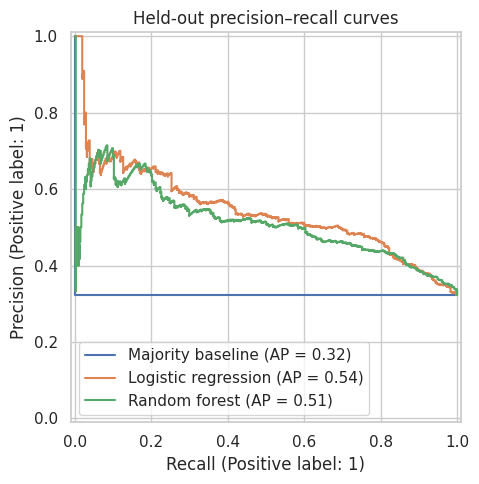

In [13]:
fig,ax=plt.subplots(figsize=(7,5))
for name,(_,prob) in predictions.items(): PrecisionRecallDisplay.from_predictions(y_test,prob,name=name,ax=ax)
ax.set_title('Held-out precision–recall curves'); plt.tight_layout(); plt.show()

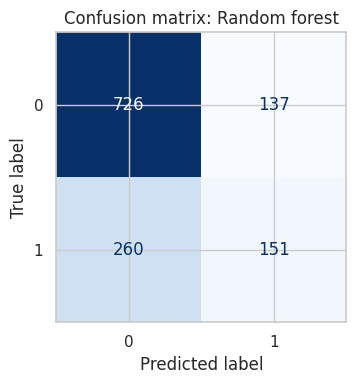

              precision    recall  f1-score   support

           0       0.74      0.84      0.79       863
           1       0.52      0.37      0.43       411

    accuracy                           0.69      1274
   macro avg       0.63      0.60      0.61      1274
weighted avg       0.67      0.69      0.67      1274



In [14]:
winner=cv_table['roc_auc_mean'].idxmax()
fig,ax=plt.subplots(figsize=(5,4))
ConfusionMatrixDisplay.from_predictions(y_test,predictions[winner][0],ax=ax,cmap='Blues',colorbar=False)
ax.set_title('Confusion matrix: '+winner); plt.tight_layout(); plt.show()
print(classification_report(y_test,predictions[winner][0],zero_division=0))

,impurity_importance
rate_marriage,0.312
yrs_married,0.167
religious,0.098
children,0.097
occupation_husb,0.090
age,0.080
occupation,0.079
educ,0.077


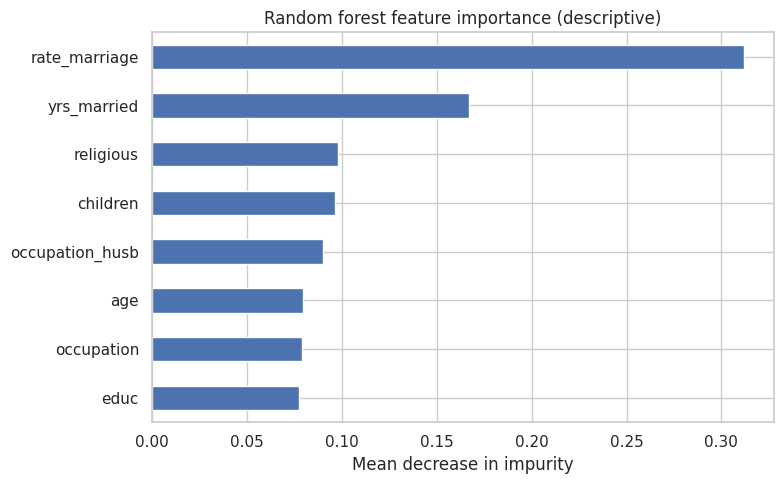

In [15]:
forest=models['Random forest']
imp=pd.Series(forest.feature_importances_,index=X.columns).sort_values(ascending=False)
display(imp.rename('impurity_importance').to_frame().round(3))
fig,ax=plt.subplots(figsize=(8,5))
imp.sort_values().plot.barh(ax=ax)
ax.set(title='Random forest feature importance (descriptive)',xlabel='Mean decrease in impurity')
plt.tight_layout(); plt.show()

### 5. Conclusions and limitations
Run the notebook from top to bottom to reproduce the tables and charts. Select the preferred model by training-only CV ROC-AUC, then interpret untouched test scores. Raw accuracy can be misleading with class imbalance. Precision–recall and balanced accuracy help reveal this. Feature importance does not establish causation.

**Limitations:** Historical and potentially nonrepresentative sample; self-reporting bias; sensitive outcome; numeric occupational codes; single holdout split; no external validation or calibration study. Do not use these models to make individual-level accusations or consequential decisions.

**Reproducibility:** The dataset is embedded in this notebook; in Google Colab select **Runtime → Run all**. No dataset upload is needed.

## References <a id="references"></a>
1. Fair, R. C. (1978). A theory of extramarital affairs. *Journal of Political Economy, 86*(1), 45–61.
2. statsmodels. Fair dataset documentation: https://www.statsmodels.org/stable/datasets/generated/fair.html
3. scikit-learn developers. User guide: https://scikit-learn.org/stable/user_guide.html
4. pandas documentation: https://pandas.pydata.org/docs/
5. Matplotlib documentation: https://matplotlib.org/stable/

The analysis and code were assembled for this project; no external notebook was copied.

**Disclaimer.** This notebook was prepared by [student name(s)] as a term project for educational purposes only. The correctness of student work is not guaranteed. The model is not suitable for making judgments about individuals.